# Моделирование и оценка — прогноз осадков на завтра в Кишинёве

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

**Охваченные этапы жизненного цикла Data Science:** шаг 5 (построение признаков), шаг 6 (моделирование), шаг 7 (оценка).

**Задача:** бинарная классификация — по метеоданным дня *t* (и предыдущих дней) предсказать, выпадут ли в день *t+1* осадки ≥ 1 мм.

**План:**
1. Строим признаки (feature engineering) без утечки информации из будущего.
2. Делим данные **хронологически**: обучение 2015–2022, валидация 2023, тест 2024–2025.
3. Задаём **базовые модели** (baseline): «дождя никогда не будет», инерционность («завтра как сегодня»), месячная климатология.
4. Обучаем 3 ML-модели: **логистическую регрессию**, **Random Forest**, **Gradient Boosting** с подбором гиперпараметров кросс-валидацией для временных рядов.
5. Выбираем порог решения на валидации и один раз оцениваем модели на тесте.
6. Интерпретируем модель (важность признаков) и проверяем ключевые показатели эффективности (KPI).

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURES, TARGET
from db import load_dataset

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve)

FIG = ROOT / "figures"; MODELS = ROOT / "models"
FIG.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET = "#E0A030", "#2B6CB0"
LR, RF, GB = "Логистическая регрессия", "Random Forest", "Gradient Boosting"
PERSIST, CLIM, NEVER = "Инерционность", "Климатология", "Дождя никогда не будет"
COLORS = {LR: "#6C8EBF", RF: "#2E8B57", GB: "#C0392B", PERSIST: "#888888", CLIM: "#BBBBBB"}
SEED = 42

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

## 1. Построение признаков (шаг 5)

Признаки вычисляются SQL-запросом `sql/03_dataset.sql` к хранилищу PostgreSQL (этап 1, ноутбук 00); та же логика повторена в `src/features.py` для модуля **Streaming** (совпадение проверено в ноутбуке 00). Главное правило: **используем только то, что известно в конце дня *t***.

На основе выводов EDA:
- убираем избыточные признаки (|ρ| > 0.95: ощущаемая температура, отдельно T_max/T_min, min/max давления, порывы, радиация, эвапотранспирация);
- добавляем **тренды** (изменение давления за 1 и 3 дня, изменение влажности) и **память** (осадки за 3 дня, число дождливых дней за последние 7, вчерашняя облачность);
- кодируем **циклически** направление ветра и день года ($\sin$, $\cos$), чтобы 31 декабря было «рядом» с 1 января;
- нормируем солнечное сияние на длительность дня (`sunshine_ratio`), чтобы признак не зависел от сезона.

In [2]:
data = load_dataset("chisinau")      # query sql/03_dataset.sql to the PostgreSQL warehouse (stage 1)
data.to_csv(ROOT / "data" / "processed" / "features.csv", index=False)
print(f"Набор признаков: {data.shape[0]} дней x {len(FEATURES)} признаков  "
      f"({data.date.min().date()} — {data.date.max().date()})")

Набор признаков: 4011 дней x 26 признаков  (2015-01-07 — 2025-12-30)


In [3]:
feat_desc = {
    "temperature_2m_mean": ("Средняя температура", "Состояние сегодня"),
    "temp_range": ("Суточная амплитуда T_max − T_min", "Производный"),
    "dew_point_2m_mean": ("Точка росы", "Состояние сегодня"),
    "dew_point_depression": ("Дефицит точки росы T − Td", "Производный"),
    "relative_humidity_2m_mean": ("Средняя относительная влажность", "Состояние сегодня"),
    "relative_humidity_2m_max": ("Максимальная относительная влажность", "Состояние сегодня"),
    "pressure_msl_mean": ("Среднее давление", "Состояние сегодня"),
    "pressure_intraday_range": ("Колебание давления за день (max − min)", "Производный"),
    "cloud_cover_mean": ("Средняя облачность", "Состояние сегодня"),
    "sunshine_ratio": ("Доля солнечного сияния от длительности дня", "Производный"),
    "precipitation_sum": ("Осадки сегодня", "Состояние сегодня"),
    "precipitation_hours": ("Часы с осадками сегодня", "Состояние сегодня"),
    "snowfall_sum": ("Снегопад сегодня", "Состояние сегодня"),
    "wind_speed_10m_max": ("Максимальная скорость ветра", "Состояние сегодня"),
    "wind_dir_sin": ("Направление ветра — sin", "Циклическое кодирование"),
    "wind_dir_cos": ("Направление ветра — cos", "Циклическое кодирование"),
    "soil_moisture_0_to_7cm_mean": ("Влажность почвы", "Состояние сегодня"),
    "vapour_pressure_deficit_max": ("Дефицит упругости пара", "Состояние сегодня"),
    "pressure_change_1d": ("Изменение давления за сутки", "Динамика"),
    "pressure_change_3d": ("Изменение давления за 3 дня", "Динамика"),
    "cloud_cover_lag1": ("Облачность вчера", "Динамика"),
    "humidity_change_1d": ("Изменение влажности за сутки", "Динамика"),
    "precip_sum_3d": ("Сумма осадков за 3 дня", "Динамика"),
    "precip_days_7d": ("Дней с осадками за последние 7", "Динамика"),
    "doy_sin": ("День года — sin", "Циклическое кодирование"),
    "doy_cos": ("День года — cos", "Циклическое кодирование"),
}
assert set(feat_desc) == set(FEATURES)
NAMES = {k: v[0] for k, v in feat_desc.items()}
pd.DataFrame([(k, *v) for k, v in feat_desc.items()], columns=["Признак", "Описание", "Группа"])

,Признак,Описание,Группа
0,temperature_2m_mean,Средняя температура,Состояние сегодня
1,temp_range,Суточная амплитуда T_max − T_min,Производный
2,dew_point_2m_mean,Точка росы,Состояние сегодня
3,dew_point_depression,Дефицит точки росы T − Td,Производный
4,relative_humidity_2m_mean,Средняя относительная влажность,Состояние сегодня
5,relative_humidity_2m_max,Максимальная относительная влажность,Состояние сегодня
6,pressure_msl_mean,Среднее давление,Состояние сегодня
7,pressure_intraday_range,Колебание давления за день (max − min),Производный
8,cloud_cover_mean,Средняя облачность,Состояние сегодня
9,sunshine_ratio,Доля солнечного сияния от длительности дня,Производный


## 2. Хронологическое разбиение данных

Во временных рядах дни **нельзя перемешивать случайно**: иначе модель «видит будущее» (соседние дни очень похожи), и результаты завышаются.
Обучаем на прошлом и проверяем на будущем — ровно как при реальной эксплуатации.

| Набор | Период | Роль |
|---|---|---|
| Обучение | 2015–2022 | обучение моделей + кросс-валидация для гиперпараметров |
| Валидация | 2023 | выбор порога решения |
| Тест | 2024–2025 | итоговая оценка, используется **один раз** |

In [4]:
train = data[data.date.dt.year <= 2022]
valid = data[data.date.dt.year == 2023]
test = data[data.date.dt.year >= 2024]
X_tr, y_tr = train[FEATURES], train[TARGET]
X_va, y_va = valid[FEATURES], valid[TARGET]
X_te, y_te = test[FEATURES], test[TARGET]

split_tbl = pd.DataFrame({
    "Период": [f"{s.date.min().date()} — {s.date.max().date()}" for s in (train, valid, test)],
    "Дней": [len(s) for s in (train, valid, test)],
    "Дней с осадками": [int(s[TARGET].sum()) for s in (train, valid, test)],
    "% положительного класса": [round(s[TARGET].mean() * 100, 1) for s in (train, valid, test)],
}, index=["Обучение", "Валидация", "Тест"])
split_tbl

,Период,Дней,Дней с осадками,% положительного класса
Обучение,2015-01-07 — 2022-12-31,2916,711,24.4
Валидация,2023-01-01 — 2023-12-31,365,87,23.8
Тест,2024-01-01 — 2025-12-30,730,161,22.1


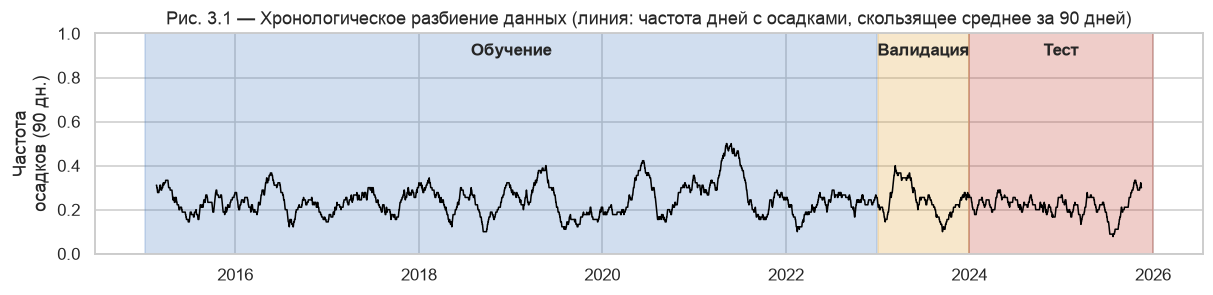

In [5]:
fig, ax = plt.subplots(figsize=(13, 2.6))
for (name, s), c in zip({"Обучение": train, "Валидация": valid, "Тест": test}.items(), ["#4A7FC1", "#E0A030", "#C0392B"]):
    ax.axvspan(s.date.min(), s.date.max(), color=c, alpha=0.25)
    ax.text(s.date.min() + (s.date.max() - s.date.min()) / 2, 0.9, name, ha="center", fontsize=11, fontweight="bold")
r = data.set_index("date")[TARGET].rolling(90, center=True).mean()
ax.plot(r.index, r.values, color="black", lw=1)
ax.set_ylabel("Частота\nосадков (90 дн.)"); ax.set_ylim(0, 1)
ax.set_title("Рис. 3.1 — Хронологическое разбиение данных (линия: частота дней с осадками, скользящее среднее за 90 дней)")
save("fig_3_1_split")

## 3. Базовые модели (baseline)

ML-модель имеет смысл, только если она **лучше простых правил**:
- **«Дождя никогда не будет»** — всегда предсказывает мажоритарный класс;
- **Инерционность** — «завтра будет как сегодня» (классический наивный прогноз);
- **Климатология** — вероятность = историческая частота дней с осадками в данном месяце (по обучающей выборке).

In [6]:
def metrics(y, proba=None, pred=None):
    m = {}
    if proba is not None:
        m["ROC-AUC"] = roc_auc_score(y, proba)
        m["PR-AUC"] = average_precision_score(y, proba)
        m["Brier"] = brier_score_loss(y, proba)
    if pred is not None:
        m["Accuracy"] = accuracy_score(y, pred)
        m["Balanced acc."] = balanced_accuracy_score(y, pred)
        m["Precision"] = precision_score(y, pred, zero_division=0)
        m["Recall"] = recall_score(y, pred)
        m["F1"] = f1_score(y, pred)
    return m

clim = train.groupby(train.date.dt.month)[TARGET].mean()
p_clim_te = test.date.dt.month.map(clim).values
pred_pers_te = (test.precipitation_sum >= 1).astype(int).values

baselines = pd.DataFrame({
    NEVER: metrics(y_te, pred=np.zeros(len(y_te), dtype=int)),
    PERSIST: metrics(y_te, pred=pred_pers_te),
    CLIM: metrics(y_te, proba=p_clim_te),
}).T
baselines.round(3)

,Accuracy,Balanced acc.,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
Дождя никогда не будет,0.779,0.500,0.000,0.000,0.000,NaN,NaN,NaN
Инерционность,0.753,0.641,0.441,0.441,0.441,NaN,NaN,NaN
Климатология,NaN,NaN,NaN,NaN,NaN,0.528,0.243,0.172


**Интерпретация.**
- У правила **«дождя никогда не будет»** самая высокая accuracy (≈ 78 %), но оно не находит ни одного дождливого дня — это **парадокс accuracy** при несбалансированных классах. Поэтому accuracy не используется как метрика успеха.
- **Инерционность** находит 44 % дождливых дней (Recall = Precision = F1 ≈ 0.44) — это реальная планка, которую нужно превзойти.
- Месячная **климатология** почти не различает дни (ROC-AUC ≈ 0.53, близко к случайному): сезон сам по себе не говорит, пойдёт ли дождь *завтра*, — только как часто идёт дождь в этом месяце.

## 4. Обучение моделей (шаг 6)

Сравниваем три семейства моделей — от простого к сложному:

| Модель | Идея | Зачем |
|---|---|---|
| **Логистическая регрессия** | линейная комбинация признаков → вероятность через сигмоиду | простая, интерпретируемая (коэффициенты), линейный ориентир |
| **Random Forest** | ансамбль деревьев решений на бутстрэп-выборках, усреднённое голосование | улавливает нелинейности и взаимодействия, устойчив к выбросам |
| **Gradient Boosting** | деревья строятся последовательно, каждое исправляет ошибки предыдущих | обычно самый точный на табличных данных |

Гиперпараметры подбираются с помощью **`TimeSeriesSplit` (5 фолдов)** на обучающей выборке: каждый фолд обучается на прошлом и проверяется на следующем за ним периоде.
Оптимизируемая метрика — **PR-AUC (Average Precision)**: она подходит для несбалансированных классов, так как сосредоточена на редком классе «дождь».

> В этом ноутбуке модели обучаются **без балансировки классов** — эффект SMOTE изучается отдельно, в ноутбуке, посвящённом 6 фундаментальным элементам.

In [7]:
cv = TimeSeriesSplit(n_splits=5)
candidates = {
    LR: (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
         {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]}),
    RF: (RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1),
         {"max_depth": [4, 8, 12, None], "min_samples_leaf": [1, 5, 20, 50], "max_features": ["sqrt", 0.5]}),
    GB: (HistGradientBoostingClassifier(random_state=SEED),
         {"learning_rate": [0.01, 0.03, 0.1], "max_depth": [2, 3, 5], "max_iter": [100, 300],
          "min_samples_leaf": [20, 50, 100]}),
}

models, cv_rows = {}, []
for name, (est, grid) in candidates.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=cv, scoring="average_precision", n_jobs=-1).fit(X_tr, y_tr)
    models[name] = gs.best_estimator_
    best = gs.cv_results_["std_test_score"][gs.best_index_]
    cv_rows.append((name, len(gs.cv_results_["params"]), gs.best_score_, best, str(gs.best_params_), time.time() - t0))
cv_tbl = pd.DataFrame(cv_rows, columns=["Модель", "Проверено комбинаций", "PR-AUC CV (среднее)", "PR-AUC CV (std)",
                                        "Лучшие гиперпараметры", "Время, с"]).set_index("Модель")
cv_tbl.round(3)

,Проверено комбинаций,PR-AUC CV (среднее),PR-AUC CV (std),Лучшие гиперпараметры,"Время, с"
Модель,,,,,
Логистическая регрессия,5,0.476,0.045,{'logisticregression__C': 0.1},3.923
Random Forest,32,0.493,0.048,"{'max_depth': 12, 'max_features': 0.5, 'min_sa...",21.559
Gradient Boosting,54,0.482,0.052,"{'learning_rate': 0.01, 'max_depth': 3, 'max_i...",3.605


**Интерпретация.** Результаты трёх моделей на кросс-валидации близки (PR-AUC ≈ 0.48–0.49), а различия между ними меньше разброса между фолдами (std ≈ 0.05). У **Random Forest** лучший средний результат — он выбирается основной моделью. То, что логистическая регрессия почти так же хороша, показывает: зависимости в основном монотонные (больше влажности → выше шанс), а нелинейности дают скромный выигрыш.

## 5. Выбор порога решения (на валидационном 2023 году)

Модели выдают **вероятность**. Стандартный порог 0.5 не оптимален, когда положительный класс редок, — модель слишком редко говорила бы «дождь».
Для каждой модели выбираем порог, максимизирующий **F1** на валидационном 2023 году (данные, которых модель не видела при обучении).

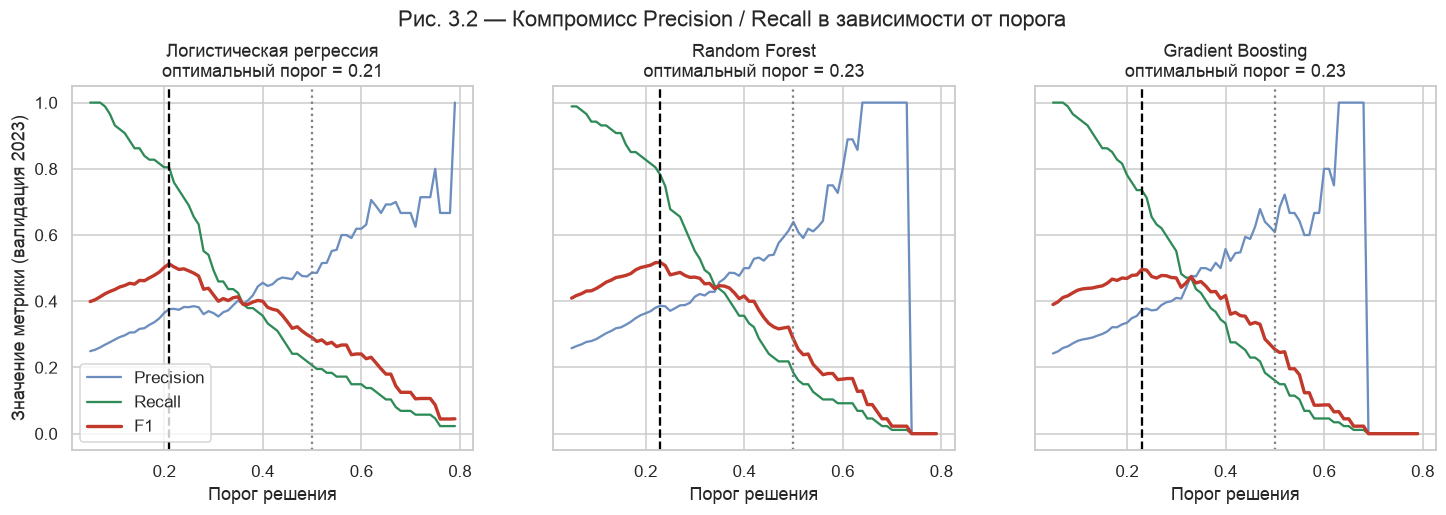

,"Оптимальный порог (F1, валидация)"
Логистическая регрессия,0.21
Random Forest,0.23
Gradient Boosting,0.23


In [8]:
thresholds = np.round(np.arange(0.05, 0.80, 0.01), 2)
thr, proba_va, proba_te = {}, {}, {}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    proba_va[name] = m.predict_proba(X_va)[:, 1]
    proba_te[name] = m.predict_proba(X_te)[:, 1]
    f1s = [f1_score(y_va, proba_va[name] >= t) for t in thresholds]
    prec = [precision_score(y_va, proba_va[name] >= t, zero_division=0) for t in thresholds]
    rec = [recall_score(y_va, proba_va[name] >= t) for t in thresholds]
    thr[name] = thresholds[int(np.argmax(f1s))]
    ax.plot(thresholds, prec, label="Precision", color="#6C8EBF")
    ax.plot(thresholds, rec, label="Recall", color="#2E8B57")
    ax.plot(thresholds, f1s, label="F1", color="#C0392B", lw=2.2)
    ax.axvline(thr[name], ls="--", color="black"); ax.axvline(0.5, ls=":", color="gray")
    ax.set_title(f"{name}\nоптимальный порог = {thr[name]:.2f}"); ax.set_xlabel("Порог решения")
axes[0].legend(); axes[0].set_ylabel("Значение метрики (валидация 2023)")
fig.suptitle("Рис. 3.2 — Компромисс Precision / Recall в зависимости от порога", y=1.04)
save("fig_3_2_thresholds")
pd.Series(thr, name="Оптимальный порог (F1, валидация)").to_frame()

**Интерпретация.** Оптимальные пороги (0.21–0.23) намного ниже 0.5 и близки к частоте положительного класса (~0.24). При стандартном пороге 0.5 модели нашли бы лишь ~20–25 % дождливых дней (F1 ≈ 0.25–0.30). Выбор порога — это **бизнес-решение**, а не только техническое: низкий порог означает меньше пропущенных дождей, но больше ложных тревог.

## 6. Итоговая оценка на тестовой выборке 2024–2025 (шаг 7)

In [9]:
rows = {name: metrics(y_te, proba_te[name], (proba_te[name] >= thr[name]).astype(int)) for name in models}
rows[PERSIST] = metrics(y_te, pred=pred_pers_te)
rows[CLIM] = metrics(y_te, proba=p_clim_te)
rows[NEVER] = metrics(y_te, pred=np.zeros(len(y_te), dtype=int))
results = pd.DataFrame(rows).T[["ROC-AUC", "PR-AUC", "Brier", "F1", "Precision", "Recall", "Balanced acc.", "Accuracy"]]
results.round(3)

,ROC-AUC,PR-AUC,Brier,F1,Precision,Recall,Balanced acc.,Accuracy
Логистическая регрессия,0.773,0.513,0.141,0.524,0.396,0.776,0.720,0.689
Random Forest,0.793,0.551,0.136,0.519,0.395,0.758,0.715,0.690
Gradient Boosting,0.796,0.527,0.138,0.533,0.404,0.783,0.728,0.697
Инерционность,NaN,NaN,NaN,0.441,0.441,0.441,0.641,0.753
Климатология,0.528,0.243,0.172,NaN,NaN,NaN,NaN,NaN
Дождя никогда не будет,NaN,NaN,NaN,0.000,0.000,0.000,0.500,0.779


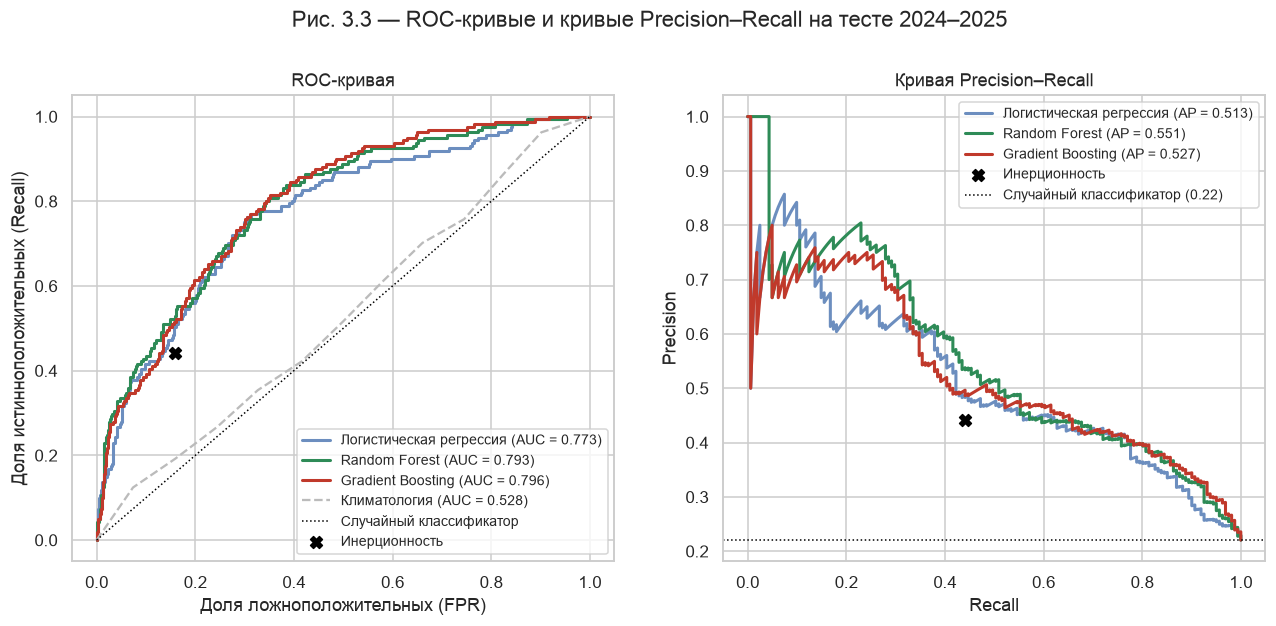

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_te, proba_te[name])
    a1.plot(fpr, tpr, color=COLORS[name], lw=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
    p, r, _ = precision_recall_curve(y_te, proba_te[name])
    a2.plot(r, p, color=COLORS[name], lw=2, label=f"{name} (AP = {results.loc[name, 'PR-AUC']:.3f})")
fpr, tpr, _ = roc_curve(y_te, p_clim_te)
a1.plot(fpr, tpr, color=COLORS[CLIM], lw=1.5, ls="--", label=f"{CLIM} (AUC = {results.loc[CLIM, 'ROC-AUC']:.3f})")
a1.plot([0, 1], [0, 1], ":", color="black", lw=1, label="Случайный классификатор")
pp, rp = results.loc[PERSIST, ["Precision", "Recall"]]
fp_rate = 1 - (balanced_accuracy_score(y_te, pred_pers_te) * 2 - rp)
a1.scatter([fp_rate], [rp], color="black", zorder=5, s=60, marker="X", label=PERSIST)
a2.scatter([rp], [pp], color="black", zorder=5, s=60, marker="X", label=PERSIST)
a2.axhline(y_te.mean(), ls=":", color="black", lw=1, label=f"Случайный классификатор ({y_te.mean():.2f})")
a1.set(xlabel="Доля ложноположительных (FPR)", ylabel="Доля истинноположительных (Recall)", title="ROC-кривая"); a1.legend(loc="lower right", fontsize=9)
a2.set(xlabel="Recall", ylabel="Precision", title="Кривая Precision–Recall"); a2.legend(loc="upper right", fontsize=9)
fig.suptitle("Рис. 3.3 — ROC-кривые и кривые Precision–Recall на тесте 2024–2025", y=1.02)
save("fig_3_3_roc_pr")

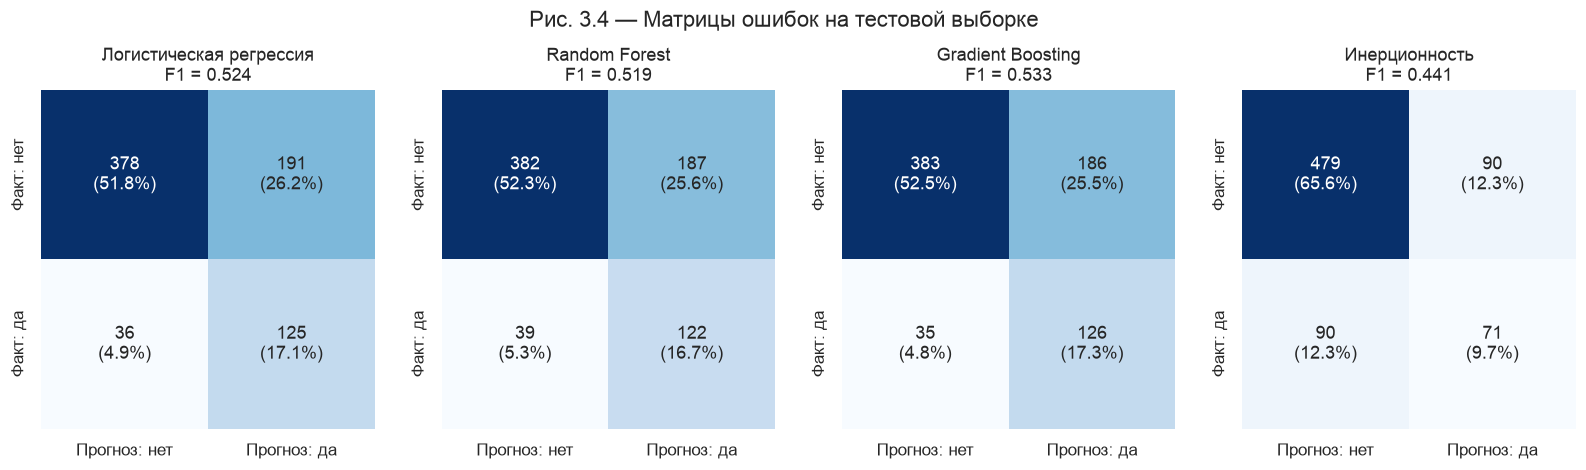

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
cms = {**{n: (proba_te[n] >= thr[n]).astype(int) for n in models}, PERSIST: pred_pers_te}
for ax, (name, pred) in zip(axes, cms.items()):
    cm = confusion_matrix(y_te, pred)
    annot = np.array([[f"{v}\n({v / cm.sum():.1%})" for v in row] for row in cm])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Прогноз: нет", "Прогноз: да"], yticklabels=["Факт: нет", "Факт: да"])
    ax.set_title(f"{name}\nF1 = {f1_score(y_te, pred):.3f}")
fig.suptitle("Рис. 3.4 — Матрицы ошибок на тестовой выборке", y=1.06)
save("fig_3_4_confusion")

**Интерпретация.**
- Все ML-модели **превосходят все базовые правила**: ROC-AUC ≈ 0.77–0.80 (против 0.53 у климатологии), F1 ≈ 0.52–0.53 (против 0.44 у инерционности).
- Random Forest находит **122 из 161** дня с осадками (Recall ≈ 0.76) против 71 у инерционности — на 51 дождливый день больше. Цена: **187 ложных тревог** (против 90 у инерционности), то есть Precision ≈ 0.40.
- Accuracy моделей (≈ 0.69–0.71) *ниже*, чем у правила «дождя никогда не будет» (0.78), — ещё одно подтверждение, что accuracy здесь обманчива.
- Различия между тремя моделями на тесте малы (у Gradient Boosting чуть выше F1 и ROC-AUC, у Random Forest — лучший PR-AUC). Мы не меняем выбор модели по результатам теста, чтобы не «подогнать» её под эту выборку.
- Точка инерционности (X на ROC-графике) лежит ниже кривых моделей: при той же доле ложных тревог модели находят больше дождливых дней.

### 6.1 Калибровка вероятностей

Хорошо откалиброванная модель, говорящая «30 % вероятность дождя», должна оказываться права примерно в 30 % таких случаев. Калибровка важна для решений (например, фермер решает по вероятности, а не по «да/нет»).

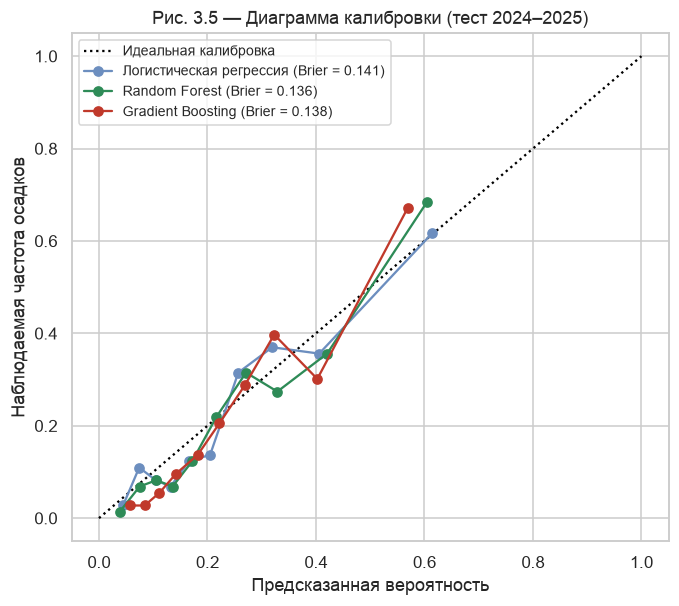

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], ":", color="black", label="Идеальная калибровка")
for name in models:
    fr, mp = calibration_curve(y_te, proba_te[name], n_bins=10, strategy="quantile")
    ax.plot(mp, fr, "o-", color=COLORS[name], label=f"{name} (Brier = {results.loc[name, 'Brier']:.3f})")
ax.set(xlabel="Предсказанная вероятность", ylabel="Наблюдаемая частота осадков",
       title="Рис. 3.5 — Диаграмма калибровки (тест 2024–2025)")
ax.legend(fontsize=9)
save("fig_3_5_calibration")

**Интерпретация.** Все модели **хорошо откалиброваны** (точки близки к диагонали) без дополнительной калибровки. Предсказанные вероятности не превышают ≈ 0.75 (лишь ≈ 9 % дней получают вероятность выше 0.5): по суточным данным одной точки модель никогда не бывает «уверена», что пойдёт дождь, — это фундаментальное ограничение доступной информации, а не алгоритма.

**Brier skill score** относительно климатологии: $BSS = 1 - \frac{0.136}{0.172} \approx 0.21$, то есть вероятности Random Forest на ~21 % лучше климатологических.

## 7. Интерпретация модели: какие признаки важны?

Используем **пермутационную важность** (permutation importance) на тестовой выборке: случайно перемешиваем один признак и смотрим, насколько падает PR-AUC.
Чем сильнее падение, тем больше модель опирается на этот признак. Метод одинаково работает для любой модели, поэтому сравнения корректны.

Выбранная модель (по PR-AUC на кросс-валидации): Random Forest


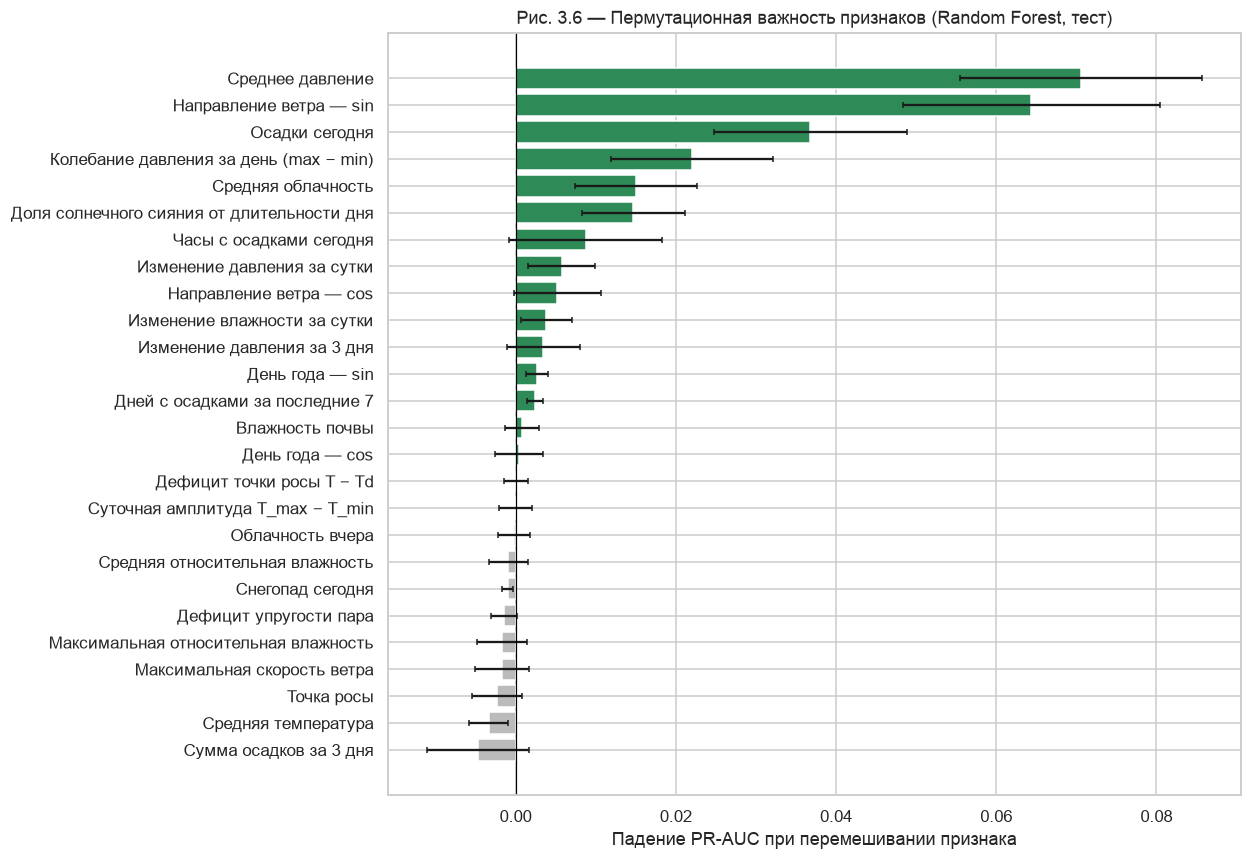

,среднее,std
Среднее давление,0.0706,0.0151
Направление ветра — sin,0.0644,0.0161
Осадки сегодня,0.0368,0.0121
Колебание давления за день (max − min),0.0220,0.0101
Средняя облачность,0.0150,0.0076
Доля солнечного сияния от длительности дня,0.0147,0.0064
Часы с осадками сегодня,0.0087,0.0095
Изменение давления за сутки,0.0058,0.0042
Направление ветра — cos,0.0052,0.0055
Изменение влажности за сутки,0.0038,0.0032


In [13]:
best_name = cv_tbl["PR-AUC CV (среднее)"].idxmax()   # the model is chosen by CV, NOT by the test set
best = models[best_name]
print(f"Выбранная модель (по PR-AUC на кросс-валидации): {best_name}")

pi = permutation_importance(best, X_te, y_te, scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("mean")
imp.index = [NAMES[i] for i in imp.index]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=np.where(imp["mean"] > 0, "#2E8B57", "#BBBBBB"), capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Падение PR-AUC при перемешивании признака")
ax.set_title(f"Рис. 3.6 — Пермутационная важность признаков ({best_name}, тест)")
save("fig_3_6_permutation_importance")
imp.sort_values("mean", ascending=False).head(10).round(4).rename(columns={"mean": "среднее", "std": "std"})

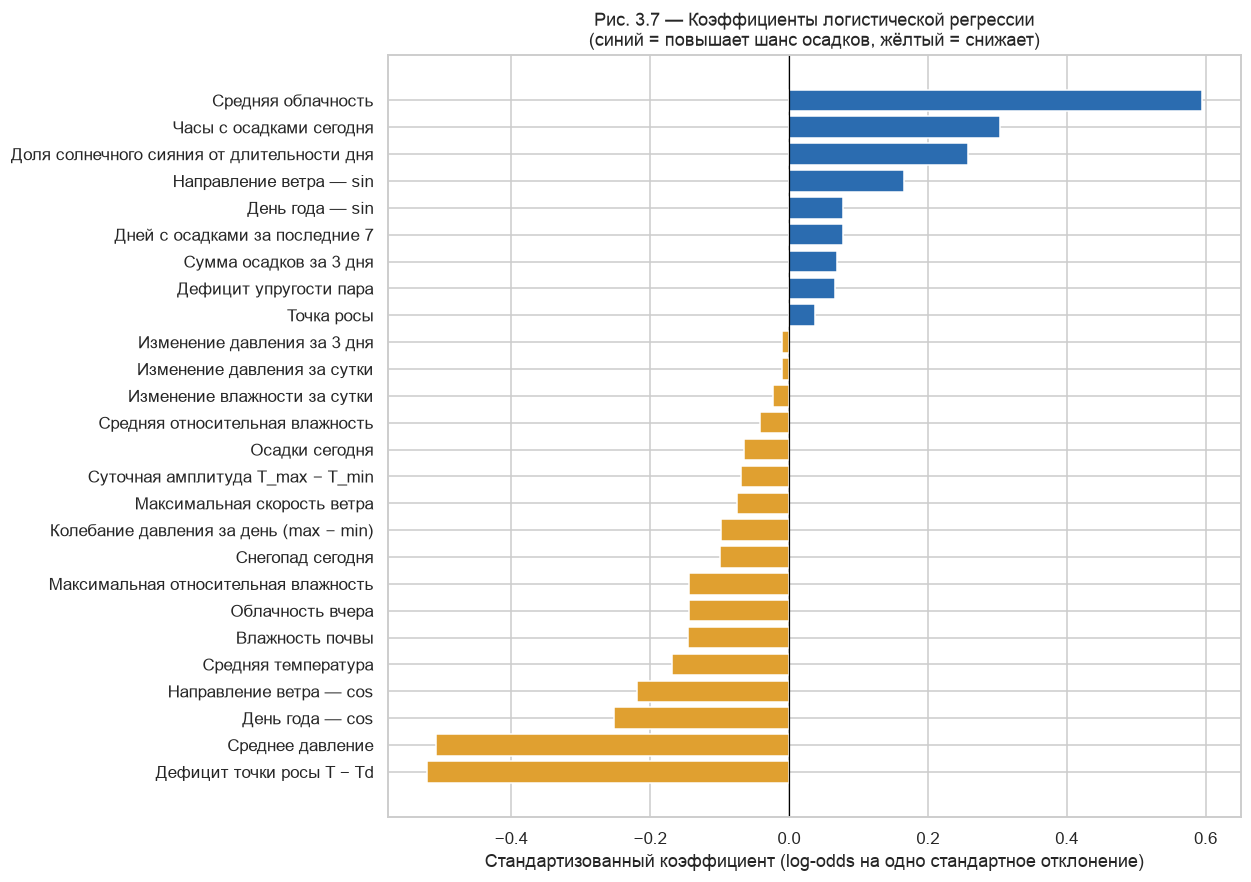

In [14]:
lr = models[LR]
coef = pd.Series(lr.named_steps["logisticregression"].coef_[0], index=[NAMES[f] for f in FEATURES]).sort_values()
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(coef.index, coef.values, color=np.where(coef > 0, C_WET, C_DRY))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Стандартизованный коэффициент (log-odds на одно стандартное отклонение)")
ax.set_title("Рис. 3.7 — Коэффициенты логистической регрессии\n(синий = повышает шанс осадков, жёлтый = снижает)")
save("fig_3_7_lr_coefficients")

**Интерпретация.**
- Для Random Forest важнее всего **среднее давление**, **направление ветра (компонента восток–запад, sin)**, **сегодняшние осадки**, **колебание давления за день**, **облачность** и **доля солнечного сияния**. Это ровно «рецепт» синоптика: низкое и неустойчивое давление + влажный ветер + облачное небо → осадки.
- Логистическая регрессия подтверждает основные физические направления: облачность повышает шанс осадков, а высокое давление и большой дефицит точки росы (сухой воздух) его снижают. Знаки компонент ветра (sin > 0 = ветер с востока, cos < 0 = ветер с юга) подтверждают вывод EDA: ветра сектора В–Ю приносят осадки.
- **Осторожно с мультиколлинеарностью:** некоторые коэффициенты логистической регрессии имеют неожиданные знаки (например, доля солнца — положительный, сегодняшние осадки — отрицательный). Это не значит, что солнце приносит дождь: коррелированные признаки (облачность / солнце, осадки / часы с осадками) «делят» эффект между собой. Отдельные коэффициенты нельзя интерпретировать изолированно; пермутационная важность надёжнее.

## 8. Анализ ошибок по сезонам

In [15]:
SEASONS = {12: "Зима", 1: "Зима", 2: "Зима", 3: "Весна", 4: "Весна", 5: "Весна",
           6: "Лето", 7: "Лето", 8: "Лето", 9: "Осень", 10: "Осень", 11: "Осень"}
season = test.date.dt.month.map(SEASONS).values
pred_best = (proba_te[best_name] >= thr[best_name]).astype(int)
srows = []
for s in ["Зима", "Весна", "Лето", "Осень"]:
    m = season == s
    srows.append((s, int(m.sum()), y_te[m].mean(), roc_auc_score(y_te[m], proba_te[best_name][m]),
                  f1_score(y_te[m], pred_best[m]), precision_score(y_te[m], pred_best[m]), recall_score(y_te[m], pred_best[m]),
                  f1_score(y_te[m], pred_pers_te[m])))
by_season = pd.DataFrame(srows, columns=["Сезон", "Дней", "% осадков", "ROC-AUC", "F1", "Precision", "Recall", "F1 инерционности"]).set_index("Сезон")
by_season.round(3)

,Дней,% осадков,ROC-AUC,F1,Precision,Recall,F1 инерционности
Сезон,,,,,,,
Зима,180,0.211,0.773,0.458,0.338,0.711,0.421
Весна,184,0.255,0.806,0.582,0.448,0.830,0.484
Лето,184,0.152,0.803,0.427,0.311,0.679,0.327
Осень,182,0.264,0.782,0.574,0.457,0.771,0.479


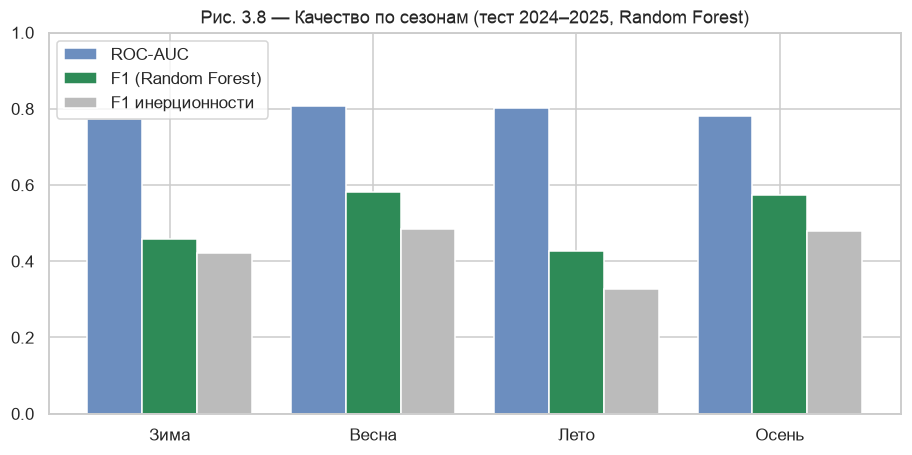

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(4); w = 0.27
ax.bar(x - w, by_season["ROC-AUC"], w, label="ROC-AUC", color="#6C8EBF")
ax.bar(x, by_season["F1"], w, label=f"F1 ({best_name})", color="#2E8B57")
ax.bar(x + w, by_season["F1 инерционности"], w, label="F1 инерционности", color="#BBBBBB")
ax.set_xticks(x, by_season.index); ax.set_ylim(0, 1); ax.legend()
ax.set_title(f"Рис. 3.8 — Качество по сезонам (тест 2024–2025, {best_name})")
save("fig_3_8_by_season")

**Интерпретация.**
- Модель **стабильна по сезонам** с точки зрения различающей способности (ROC-AUC 0.77–0.81) и обыгрывает инерционность в каждом сезоне.
- Лучшие результаты **весной и осенью** (F1 ≈ 0.57–0.58): осадки приходят в основном с **атмосферными фронтами**, которые заранее проявляются в падении давления и росте облачности.
- **Летом** F1 наименьший (≈ 0.43): летние дожди часто **конвективные** (локальные ливни, грозы), формируются за несколько часов и плохо видны в суточных данных предыдущего дня. К тому же летом положительный класс ещё реже (15 %).
- **Зимой** наименьший ROC-AUC (0.77): воздух почти всегда влажный и облачный, поэтому дни с осадками и без них выглядят похоже.

## 9. Ключевые показатели эффективности (KPI)

KPI (требование п. 1.4.1 шаблона) переводят технические метрики в критерии успеха поставленной задачи.

In [17]:
r_best = results.loc[best_name]
r_pers, r_clim = results.loc[PERSIST], results.loc[CLIM]
kpi = pd.DataFrame([
    ("KPI-1", "Различающая способность (ROC-AUC)", "≥ 0.75", r_best["ROC-AUC"], r_best["ROC-AUC"] >= 0.75),
    ("KPI-2", "Обнаружение дней с осадками (Recall)", "≥ 0.70", r_best["Recall"], r_best["Recall"] >= 0.70),
    ("KPI-3", "Качество тревог для редкого класса (PR-AUC)", "≥ 2 × частота класса", r_best["PR-AUC"],
     r_best["PR-AUC"] >= 2 * y_te.mean()),
    ("KPI-4", "Прирост F1 относительно инерционности", "≥ +0.05", r_best["F1"] - r_pers["F1"], r_best["F1"] - r_pers["F1"] >= 0.05),
    ("KPI-5", "Качество вероятностей (Brier skill score vs. климатология)", "> 0", 1 - r_best["Brier"] / r_clim["Brier"],
     1 - r_best["Brier"] / r_clim["Brier"] > 0),
    ("KPI-6", "Доля ложных тревог (1 − Precision)", "≤ 0.60", 1 - r_best["Precision"], 1 - r_best["Precision"] <= 0.60),
    ("KPI-7", "Стабильность по сезонам (минимальный ROC-AUC)", "≥ 0.70", by_season["ROC-AUC"].min(), by_season["ROC-AUC"].min() >= 0.70),
], columns=["Код", "Показатель", "Цель", "Достигнутое значение", "Достигнут"]).set_index("Код")
kpi["Достигнутое значение"] = kpi["Достигнутое значение"].round(3)
kpi["Достигнут"] = kpi["Достигнут"].map({True: "да", False: "нет"})
kpi

,Показатель,Цель,Достигнутое значение,Достигнут
Код,,,,
KPI-1,Различающая способность (ROC-AUC),≥ 0.75,0.793,да
KPI-2,Обнаружение дней с осадками (Recall),≥ 0.70,0.758,да
KPI-3,Качество тревог для редкого класса (PR-AUC),≥ 2 × частота класса,0.551,да
KPI-4,Прирост F1 относительно инерционности,≥ +0.05,0.078,да
KPI-5,Качество вероятностей (Brier skill score vs. к...,> 0,0.210,да
KPI-6,Доля ложных тревог (1 − Precision),≤ 0.60,0.605,нет
KPI-7,Стабильность по сезонам (минимальный ROC-AUC),≥ 0.70,0.773,да


**Интерпретация.** Модель достигает **6 из 7 KPI**. KPI-6 (доля ложных тревог ≤ 60 %) не достигнут на грани (60.5 %): чтобы находить ~76 % дождливых дней, модель допускает ~6 ложных тревог из 10. Это компромисс, выбранный порогом по F1; если конечный пользователь предпочитает меньше ложных тревог (например, организаторы мероприятий), порог можно поднять ценой меньшего Recall (см. рис. 3.2).

## 10. Сохранение модели

In [18]:
bundle = {"model": best, "model_name": best_name, "threshold": float(thr[best_name]), "features": FEATURES,
          "trained_on": "2015–2022", "threshold_tuned_on": "2023"}
joblib.dump(bundle, MODELS / "baseline_model.joblib")
results.round(4).to_csv(MODELS / "test_results.csv")
print(f"Сохранено: models/baseline_model.joblib ({best_name}, порог {thr[best_name]:.2f})")

Сохранено: models/baseline_model.joblib (Random Forest, порог 0.23)


## 11. Выводы

1. **Построение признаков** превратило 26 исходных переменных в 26 признаков без сильной избыточности, включая тренды, память и циклическое кодирование — все они вычислимы в реальном времени.
2. **Корректная оценка** для временных рядов: хронологическое разбиение, `TimeSeriesSplit`, порог выбран на валидации, тест использован один раз.
3. **Все ML-модели превосходят наивные базовые правила**; Random Forest (выбран по CV) на 2024–2025 даёт: ROC-AUC ≈ 0.79, PR-AUC ≈ 0.55, Recall ≈ 0.76, F1 ≈ 0.52 (+0.08 к инерционности), Brier skill score ≈ 0.21 относительно климатологии.
4. Модели **хорошо откалиброваны**, но редко «уверены» (вероятности < 0.75) — ограничение информации суточных данных одной точки.
5. **Главные факторы** завтрашних осадков: давление и его изменение, направление ветра (В–Ю), сегодняшние осадки и облачность — в согласии с синоптической метеорологией.
6. Слабые места: **лето** (конвективные дожди) и высокая доля **ложных тревог**.

**Ограничения:** одна точка сетки, суточное разрешение, данные реанализа (не станции). Профессиональные численные прогнозы (физические модели атмосферы) точнее; цель этой работы — продемонстрировать жизненный цикл Data Science, а не конкурировать с метеослужбой.

**Следующие шаги** (глава 2, 6 элементов): **SMOTE** (балансировка классов vs. `class_weight` vs. ничего), **Noise** (устойчивость к ошибкам датчиков), **Bias** (обучение на искажённых данных), **Decision Boundaries** (PCA / t-SNE), **Streaming** и **RTAP** (прогноз день за днём и переобучение).